# Estimando decaimento multi exponencial utilizando Matrix Pencil
## Resumão
- Faz uma matriz de Hankel $Y$ (com um hiperparâmetro $L$)
- Tira a SVD $Y = U\Sigma V$
- Estima M com base nos valores singulares normalizados $\sigma_M/\sigma_0 \approx 10^{-p}$
- Extrai duas matrizes $V_1$ e $V_2$, submatrizes de $V$
- Os argumento das exponenciais $b_i$ são os autovalores de $V_2^T V_1$
- Monta o kernel e estima as amplitudes por LSTSQ $A = B^\dagger [y(t)]^T $

In [1]:
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
from src import (edc_synth,     # Gera uma EDC artifical
                 tvec,          # Time vector
                 MatrixPencil,  # Abstração "estilo sklearn" para o método
                 DataPreparer   # Subamostragem, crop...
                 )

_dB = lambda x: 10*np.log10(x + np.finfo(float).eps)
fs = 44100
NFFT = 2**(20)

## Aplicando o procedimento à EDCs
Para ilustrar, eu gerei uma EDC multi exponencial com dois TRs (~2s e ~7s).


### Preprocessamento das EDCs
 Para fazer o Matrix Pencil funcionar nessa aplicação:
- Subamostro a EDC em intervalos de 10 ms
  - $\mathbf{Y}$ fica grande demais para caber na RAM
- Corto a EDC nos primeiros segundos da resposta.
  - Mesmo problema com as dimensões de $\mathbf{Y}$
  - Utilizar a EDC completa introduz viezes por conta da cauda de ruído (e intervalo finito de integração, em um caso verdadeiro)

### Hiperparâmetros do Matrix Pencil ($L$ e $p$)
- $L$: 
  - observei que deixar $L=N/2$ em geral oferece melhor separação.
  - Valores menores fazem o método tender à aproximação polinomial
- $p$:
  - Valores muito baixos($p=2$ e $p=3$) fazem o modelo subestimar o número de exponenciais
  - $p=7$ faz o modelo sobrestimar o número de exponenciais.
  - Fixei $p=5$


TR verdadeiro: [3.28036303, 7.54766463]
TR estimado: [3.28056011 7.54586818]
Amplitudes verdadeiras: [0.4, 0.02]
Amplitudes estimadas: [0.40000095 0.01999377]


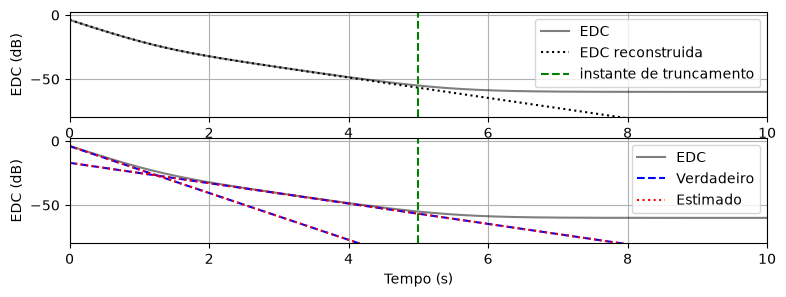

In [ ]:
t = tvec(NFFT,fs)
exp_true = edc_synth([3.28036303, 7.54766463],[0.4, 2E-2],t,60)
EDC_true = exp_true.sum(axis=0)

data = (DataPreparer(EDC_true,t,fs,)
                    .truncate_time(max_time=5,step=10E-3))
matpen = (MatrixPencil(p=-5, pencil_param=1/2,)
                       .fit(data.X,data.dt))

exp_estm = edc_synth(matpen.RT,matpen.amplitudes,t,0)
EDC_estm = exp_estm[:-1,:].sum(axis=0)

plt.figure(figsize=(9,3))
ax1 = plt.subplot(211)
ax1.plot(t,_dB(EDC_true),color='black',alpha=.5,label='EDC')
ax1.plot(t,_dB(EDC_estm),linestyle='dotted',label='EDC reconstruida',color='black')

ax2=plt.subplot(212)
ax2.plot(t,_dB(EDC_true),color='black',alpha=.5,label='EDC')
ax2.plot(t,_dB(exp_true[0]),linestyle='dashed',color='blue',label='Verdadeiro')
ax2.plot(t,_dB(exp_true[1]),linestyle='dashed',color='blue')
ax2.plot(t,_dB(exp_estm[0]),linestyle='dotted',color='red',label='Estimado')
ax2.plot(t,_dB(exp_estm[1]),linestyle='dotted',color='red')
ax2.set_xlabel('Tempo (s)')

ax1.axvline(5,color='green',linestyle='dashed',label='instante de truncamento')
ax2.axvline(5,color='green',linestyle='dashed')

for ax in [ax1,ax2]:
    ax.set_ylim(-80,2)
    ax.set_title(f'')
    ax.grid()
    ax.legend()
    ax.set_ylabel('EDC (dB)')
    ax.set_xlim(0,10)

print(f'TR verdadeiro: {[3.28036303, 7.54766463]}')
print(f'TR estimado: {matpen.RT}')

print(f'Amplitudes verdadeiras: {[0.4, 2E-2]}')
print(f'Amplitudes estimadas: {matpen.amplitudes}')


## Avaliando o erro
- Foram testadas curvas de decaimento com **máximo de 4 exponenciais**
- Cada exponencial possui TR variando entre 1---12 s
- Cada exponencial tinha no máximo 20 dB de diferença em relação à exponencial de maior amplitude
- Assume-se que o nível de ruído $L_\mathrm{noise}$ é conhecido, e a região de análise do MSE foi limitada ao intervalo $t=[0, t_{L_\mathrm{noise} + 10 \text{dB}}]$
  - Reconstrui a EDC e calculei o MSE com a EDC original (em escala linear)
- Foram realizadas 150 sorteios das variáveis

In [ ]:
def MSE(X_true,X_approx):
    return np.linalg.norm(X_true-X_approx)**2/len(X_true)

rng = np.random.default_rng(42)
n_repetitions = 150
RT_min,RT_max= 1, 12
max_snr_db = 30
N_level = -60
t = tvec(NFFT,fs)

err = np.zeros(n_repetitions)
M_true = np.zeros(n_repetitions)
M_estm = np.zeros(n_repetitions)

E_true = []
E_estm = []
for i in tqdm(range(n_repetitions),desc='trying',disable=False):
    n_exponentials = rng.integers(1,4+1)
    TR_values = np.sort(
        rng.random(n_exponentials)*(RT_max-RT_min) + RT_min
        )

    TR_amplitudes = -(np.random.random(n_exponentials)*max_snr_db).round(1)
    TR_amplitudes = 1/(10**(TR_amplitudes/10))
    TR_amplitudes /= np.sum(TR_amplitudes)

    EDC_true = edc_synth(TR_values, TR_amplitudes, t, abs(N_level)).sum(axis=0)

    t_trunc=t[ abs(_dB(EDC_true) + abs(N_level) -10).argmin()].round(2)

    data = (DataPreparer(EDC_true,t,fs,
                        verbose=False
                        ).truncate_time(max_time=t_trunc,
                                        step=10E-3))
    pencil= (MatrixPencil(p=-5, 
                        pencil_param=1/2,
                        verbose=False
                        ).fit(data.X,data.dt))
    
    EDC_estm = edc_synth(pencil.RT,pencil.amplitudes,t,0).sum(axis=0)
    data_estm = (DataPreparer(EDC_estm,t,fs,
                    verbose=False
                    ).truncate_time(max_time=t_trunc,
                                    step=10E-3))

    err[i] = MSE(data.X, data_estm.X)
    M_true[i] = n_exponentials
    M_estm[i] = len(pencil.RT)
    E_true.append(data.X)
    E_estm.append(data_estm.X)

trying: 100%|██████████| 150/150 [00:58<00:00,  2.56it/s]


### Comparando reconstrução
Algumas EDCs amostradas aleatóriamente

Text(0, 0.5, 'EDC (dB)')

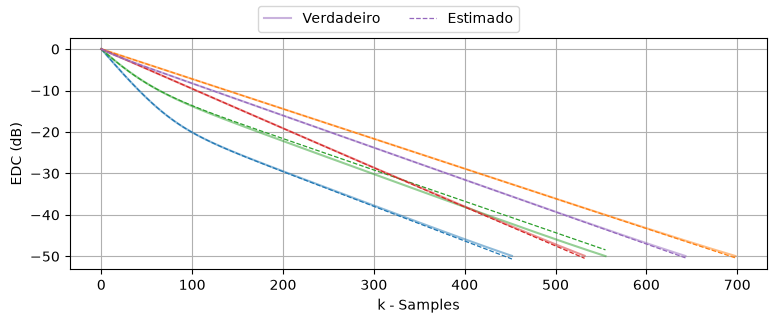

In [71]:
fig =plt.figure(figsize=(9,3))
for i in rng.integers(0,n_repetitions,5):
    lt = plt.plot(_dB(E_true[i]),alpha=.5)
    le = plt.plot(_dB(E_estm[i]),color=lt[0].get_color(),linewidth=.9,linestyle='dashed')
plt.grid()
fig.legend([lt[0],le[0]],['Verdadeiro','Estimado'],ncols=2,loc='upper center')
plt.xlabel('k - Samples')
plt.ylabel('EDC (dB)')

### Erro baseado no número de exponenciais $M$
Uma breve investigação de como o algortimo se comporta à medida que o número de exponenciais do sinal de entrada aumenta.

- Subplot 1: o quanto o método estima $M$ errado?
- Subplot 2: Erro de reconstrução médio por número de exponenciais 

done


Text(0.5, 0, '$M$ Real')

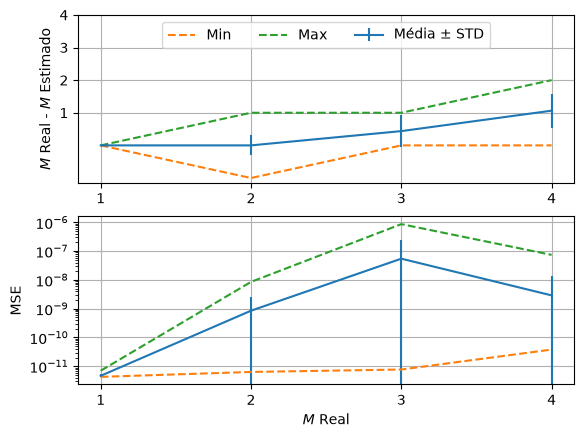

In [73]:
# plt.figure()
unique_M = np.unique(M_true)
M_err_min = np.zeros(unique_M.shape)
M_err_max = np.zeros(unique_M.shape)
M_err_mean = np.zeros(unique_M.shape)
M_err_std = np.zeros(unique_M.shape)
M_MSE_mean = np.zeros(unique_M.shape)
M_MSE_std = np.zeros(unique_M.shape)
M_MSE_min = np.zeros(unique_M.shape)
M_MSE_max = np.zeros(unique_M.shape)
for i,M in enumerate(unique_M):
    idx_M = np.where(M_true==M)[0]
    arr_misses = M_true[idx_M]-M_estm[idx_M]
    M_err_min[i] = arr_misses.min()
    M_err_max[i] = arr_misses.max()
    M_err_mean[i] = arr_misses.mean()
    M_err_std[i] = arr_misses.std()
    M_MSE_mean[i] = err[idx_M].mean()
    M_MSE_std[i] = err[idx_M].std()
    M_MSE_min[i] = err[idx_M].min()
    M_MSE_max[i] = err[idx_M].max()
print('done')

plt.subplot(211)
plt.errorbar(unique_M,M_err_mean,yerr=M_err_std,label='Média $\\pm$ STD')
plt.plot(unique_M,M_err_min,label='Min',linestyle='dashed')
plt.plot(unique_M,M_err_max,label='Max',linestyle='dashed')
plt.legend(ncols=3,loc='upper center')
plt.grid()
plt.yticks(unique_M)
plt.xticks(unique_M)
plt.ylabel('$M$ Real - $M$ Estimado')
plt.subplot(212)
plt.errorbar(unique_M,M_MSE_mean,yerr=M_MSE_std)
plt.plot(unique_M,M_MSE_min,label='Min',linestyle='dashed')
plt.plot(unique_M,M_MSE_max,label='Max',linestyle='dashed')
plt.xticks(unique_M)
plt.ylabel('MSE')
plt.yscale('log')
plt.grid()
plt.xlabel('$M$ Real')

## Brainstorming
Algumas ideias de como abordar as "pontas soltas"
### Estimando o intervalo de truncamento
1. Adaptar o método de lundeby para entregar dois instantes:
   - $T_\mathrm{cross}$: crosspoint de ruído; e
   - $T_\mathrm{cross}+10~\mathrm{dB}$: para truncar a EDC.
2. Lundeby + compensar truncamento (Guski, Vorlander)
   - O método de compensação envolve assumir decaimento exponencial

### Subamostrar o sinal
- Intervalos fixos de 10 ms (estilo Lundeby)
- Intervalo variável dependente do $T_{20}$ (Estilo ISO 3382 / Berzborn)

### Parâmetro $p$
- Fixar
- Estimar baseado em alguma curvatura da EDC
- Estimar baseado no SNR